In [1]:
import pandas as pd

In [2]:
file = pd.read_excel('./2025-2021.xlsx', sheet_name='Лист1')
file2 = pd.read_excel('./2025-2021.xlsx', sheet_name='Лист2')

In [27]:
file.head(20)

,Наименование показателя,Код строки,На 31 декабря 2025 г.2,На 31 декабря 2024 г.3,На 31 декабря 2023 г.4,На 31 декабря 2022 г.,На 31 декабря 2021 г.,На 31 декабря 2020 г.,Ср 2025,Ср 2024,Ср 2023,Ср 2022,Ср 2021
0,Нематериальные активы,1110.0,9587,11362,6061,8719,11515,3778,10474,8711,7390,10117,7646.5
1,Основные средства,1150.0,381833,445494,491644,422911,316257,302629,413663,468569,457277,369584,309443.0
2,Финансовые вложения,1170.0,0,44500,10500,0,0,0,22250,27500,5250,0,0.0
3,Отложенные налоговые активы,1180.0,55586,12602,19686,15014,14480,58497,34094,16144,17350,14747,36488.5
4,Прочие внеоборотные активы,1190.0,41487,11228,2144,24567,0,0,26357,6686,13355,12283,0.0
5,Итого по разделу I,1100.0,488494,525186,530035,471211,342253,364904,506840,527610,500623,406732,353578.5
6,Запасы,1210.0,544877,479684,324572,514415,289139,286941,512280,402128,419493,401777,288040.0
7,Налог на добавленную стоимость по приобретенны...,1220.0,17,319,14,282,242,1,168,166,148,262,121.5
8,Дебиторская задолженность,1230.0,8702717,7239973,5512487,4584786,5610150,2158832,7971345,6376230,5048636,5097468,3884491.0
9,Денежные средства и денежные эквиваленты,NaN,2941,1504,1913,1084,1202,987,2222,1708,1498,1143,1094.5


In [34]:
file2.head(20)

,Наименование показателя,Код строки,За 2025 г.2,За 2024 г.3,За 2023 г.,За 2022 г.,За 2021 г.
0,Выручка,2110.0,8366921,6493136,5797340,4685433,4078159
1,Себестоимость продаж,2120.0,-5923267,-4958377,-4388532,-3688930,-3328217
2,Валовая прибыль (убыток),2100.0,2443654,1534759,1408808,996503,749942
3,Коммерческие расходы,2210.0,-595404,-522258,-451231,-311891,-322396
4,Управленческие расходы,2220.0,-104728,-88304,-80565,-59510,-62616
5,Прибыль (убыток) от продаж,2200.0,1743522,924197,877012,625102,364930
6,Проценты к получению,2320.0,4373,37992,245,134,77
7,Проценты к уплате,2330.0,-461963,-113866,-131613,-198868,-68133
8,Прочие доходы,2340.0,37246,127036,105005,143676,284223
9,Прочие расходы,2350.0,-895280,-147563,-264319,-407070,-338239


## Перечень обязательных финансовых показателей для анализа
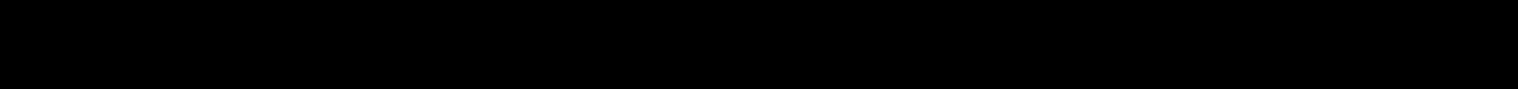
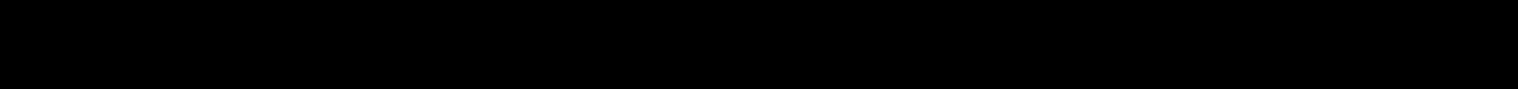
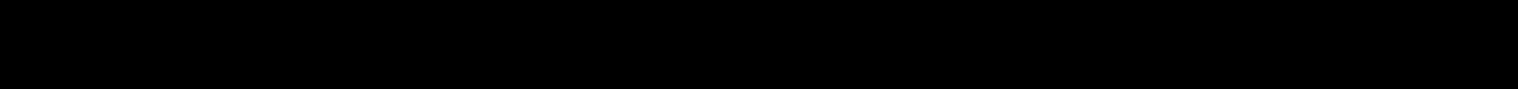

### 1. Показатели ликвидности и платежеспособности
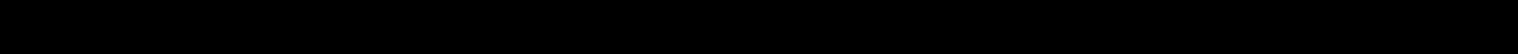

Классификация активов по ликвидности:
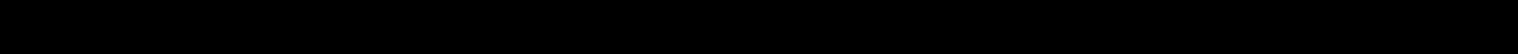

А1 – Наиболее ликвидные активы
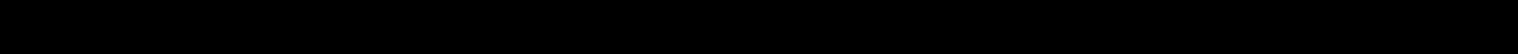

In [41]:
# Перевод в int
for idx in range(2, 13):
  col_name = file.columns[idx]
  file[col_name] = (
      pd.to_numeric(
          file[col_name]
          .astype(str)
          .str.replace(' ', '', regex=False)
          .str.replace('\xa0', '', regex=False)
          .str.replace(',', '.', regex=False),
          errors='coerce',
      )
      .fillna(0)
      .astype(int)
  )

In [33]:
for idx in range(2, len(file2.columns)):
  col_name = file2.columns[idx]
  s = file2[col_name].astype(str)

  # Проверяем, было ли число в круглых скобках (признак отрицательного значения)
  is_negative = s.str.contains(r"\(.*\)", regex=True)

  # Очищаем строку от скобок, пробелов и спецсимволов
  cleaned = (
      s.str.replace(r"[\s\xa0()]", "", regex=True)
      .str.replace(",", ".", regex=False)
  )

  # Превращаем в числа, заменяя ошибки на 0, и возвращаем знак минус для скобок
  numeric_col = pd.to_numeric(cleaned, errors="coerce").fillna(0)
  file2[col_name] = numeric_col.where(~is_negative, -numeric_col).astype(int)

In [7]:
A1 = (
    file[file.iloc[:, 0] == "Денежные средства и денежные эквиваленты"].iloc[
        0, 2:7
    ]
    + file[file.iloc[:, 0] == "Финансовые вложения"].iloc[0, 2:7]
)

display(A1)

На 31 декабря 2025 г.2     2941
На 31 декабря 2024 г.3    46004
На 31 декабря 2023 г.4    12413
На 31 декабря 2022 г.      1084
На 31 декабря 2021 г.      1202
dtype: object

А2 – Быстрореализуемые активы

In [9]:
A2 = (
    file[file.iloc[:, 0] == "Дебиторская задолженность"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Запасы"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Прочие оборотные активы"].iloc[0, 2:7]
)

display(A2)

На 31 декабря 2025 г.2    9353333
На 31 декабря 2024 г.3    7747449
На 31 декабря 2023 г.4    5845323
На 31 декабря 2022 г.     5105865
На 31 декабря 2021 г.     5908899
dtype: object

А3 – Медленно реализуемые активы
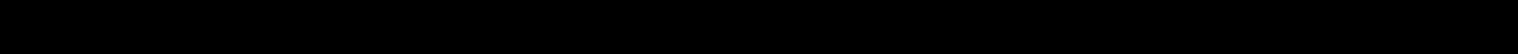

In [11]:
A3 = (
    file[file.iloc[:, 0] == "Запасы"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Налог на добавленную стоимость по приобретенным ценностям"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Прочие оборотные активы"].iloc[0, 2:7]
)

display(A3)

На 31 декабря 2025 г.2    650633
На 31 декабря 2024 г.3    507795
На 31 декабря 2023 г.4    332850
На 31 декабря 2022 г.     521361
На 31 декабря 2021 г.     298991
dtype: object

А4 – Труднореализуемые активы

In [12]:
A4 = (
    file[file.iloc[:, 0] == "Итого по разделу I"].iloc[0, 2:7]
)

display(A4)

На 31 декабря 2025 г.2    488494
На 31 декабря 2024 г.3    525186
На 31 декабря 2023 г.4    530035
На 31 декабря 2022 г.     471211
На 31 декабря 2021 г.     342253
Name: 5, dtype: object

In [13]:
current = (
    file[file.iloc[:, 0] == "Итого по разделу II"].iloc[0, 2:7]
)

display(current)

На 31 декабря 2025 г.2    9356291
На 31 декабря 2024 г.3    7749272
На 31 декабря 2023 г.4    5847250
На 31 декабря 2022 г.     5107231
На 31 декабря 2021 г.     5910343
Name: 12, dtype: object

In [14]:
short = (
    file[file.iloc[:, 0] == "Итого по разделу V"].iloc[0, 2:7]
)

display(short)

На 31 декабря 2025 г.2    3683576
На 31 декабря 2024 г.3    3823431
На 31 декабря 2023 г.4    4104128
На 31 декабря 2022 г.     3732182
На 31 декабря 2021 г.     3201400
Name: 27, dtype: object

Коэффициент абсолютной ликвидности

In [15]:
A1 / short

На 31 декабря 2025 г.2    0.000798
На 31 декабря 2024 г.3    0.012032
На 31 декабря 2023 г.4    0.003025
На 31 декабря 2022 г.      0.00029
На 31 декабря 2021 г.     0.000375
dtype: object

Коэффициент быстрой (срочной) ликвидности

In [16]:
(A1 + A2) / short

На 31 декабря 2025 г.2    2.539998
На 31 декабря 2024 г.3     2.03834
На 31 декабря 2023 г.4    1.427279
На 31 декабря 2022 г.     1.368355
На 31 декабря 2021 г.     1.846099
dtype: object

Коэффициент текущей ликвидности

In [17]:
current / short

На 31 декабря 2025 г.2    2.540002
На 31 декабря 2024 г.3    2.026785
На 31 декабря 2023 г.4    1.424724
На 31 декабря 2022 г.      1.36843
На 31 декабря 2021 г.     1.846174
dtype: object

### 2. Показатели финансовой устойчивости

In [19]:
# Собственный капитал
equity = file[
    file.iloc[:, 0].str.contains("Итого по разделу III")
].iloc[0, 2:7]

# Валюта баланса
total_balance = file[
    file.iloc[:, 0].str.contains("БАЛАНС (актив)")
].iloc[0, 2:7]

# Внеоборотные активы
non_current_assets = file[
    file.iloc[:, 0].str.contains("Итого по разделу I")
].iloc[0, 2:7]

# Оборотные активы
current_assets = file[
    file.iloc[:, 0].str.contains("Итого по разделу II")
].iloc[0, 2:7]

# Долгосрочные обязательства
long_term_liabilities = file[
    file.iloc[:, 0].str.contains("Итого по разделу IV")
].iloc[0, 2:7]

# Заемный капитал
borrowed_capital = total_balance - equity

Коэффициент автономии (независимости)
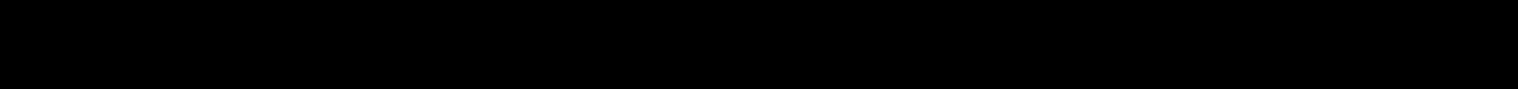

In [22]:
equity / total_balance

На 31 декабря 2025 г.2    0.157287
На 31 декабря 2024 г.3    0.269949
На 31 декабря 2023 г.4    0.247927
На 31 декабря 2022 г.     0.199655
На 31 декабря 2021 г.     0.151065
dtype: object

Коэффициент финансового рычага (плечо финансового рычага)

In [23]:
borrowed_capital / equity

На 31 декабря 2025 г.2    5.357816
На 31 декабря 2024 г.3    2.704403
На 31 декабря 2023 г.4    3.033441
На 31 декабря 2022 г.     4.008648
На 31 декабря 2021 г.     5.619683
dtype: object

Коэффициент обеспеченности собственными оборотными средствами

In [24]:
(equity - non_current_assets) / current_assets

На 31 декабря 2025 г.2    0.113288
На 31 декабря 2024 г.3    0.220472
На 31 декабря 2023 г.4    0.179754
На 31 декабря 2022 г.     0.125812
На 31 декабря 2021 г.     0.101905
dtype: object

Коэффициент долгосрочной финансовой независимости

In [25]:
(equity + long_term_liabilities) / total_balance

На 31 декабря 2025 г.2    0.625835
На 31 декабря 2024 г.3    0.537924
На 31 декабря 2023 г.4    0.356446
На 31 декабря 2022 г.     0.330963
На 31 декабря 2021 г.     0.487989
dtype: object

### 3. Показатели рентабельности (эффективности)

In [71]:
profit = file2[file2.iloc[:, 0] == "Чистая прибыль (убыток)"].iloc[0, 2:7]
revenue = file2[file2.iloc[:, 0] == "Выручка"].iloc[0, 2:7]
self_cost = file2[file2.iloc[:, 0] == "Себестоимость продаж"].iloc[0, 2:7]
sell_profit = file2[file2.iloc[:, 0] == "Прибыль (убыток) от продаж"].iloc[0, 2:7]
avg_active = file[file.iloc[:, 0] == "БАЛАНС (актив)"].iloc[0, 8:13] # Средняя стоимость активов
avg_cap = file[file.iloc[:, 0] == "Итого по разделу III"].iloc[0, 8:13]


Рентабельность продаж (ROS)
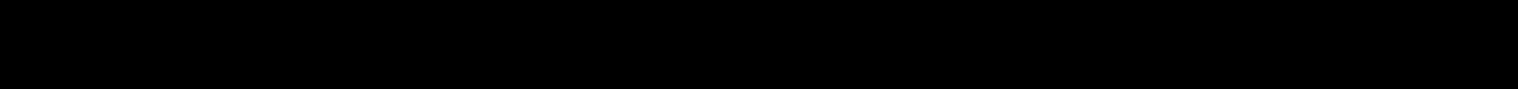

In [60]:
(profit / revenue) * 100

За 2025 г.2    3.762101
За 2024 г.3    10.05029
За 2023 г.     8.061301
За 2022 г.     2.758955
За 2021 г.     4.737603
dtype: object

Рентабельность активов (ROA)

In [66]:
p_vals = pd.to_numeric(profit.values, errors="coerce")
a_vals = pd.to_numeric(avg_active.values, errors="coerce")

In [68]:
roa_result = (p_vals / a_vals) * 100
roa_series = pd.Series(
    roa_result, index=["2025", "2024", "2023", "2022", "2021"]
)
display(roa_series)

2025    3.474450
2024    8.907869
2023    7.817861
2022    2.185252
2021    4.256672
dtype: float64

Рентабельность собственного капитала (ROE)

In [69]:
p_vals = pd.to_numeric(profit.values, errors="coerce")
a_vals = pd.to_numeric(avg_cap.values, errors="coerce")

In [70]:
roa_result = (p_vals / a_vals) * 100
roa_series = pd.Series(
    roa_result, index=["2025", "2024", "2023", "2022", "2021"]
)
display(roa_series)

2025    16.645197
2024    34.213156
2023    34.683828
2022    12.560705
2021    22.787176
dtype: float64

Рентабельность продукции (себестоимости)

In [72]:
(sell_profit / self_cost) * 100

За 2025 г.2   -29.435141
За 2024 г.3   -18.639103
За 2023 г.    -19.984177
За 2022 г.    -16.945347
За 2021 г.     -10.96473
dtype: object

### 4. Показатели деловой активности (оборачиваемости)

Оборачиваемость дебиторской задолженности

Оборачиваемость запасов
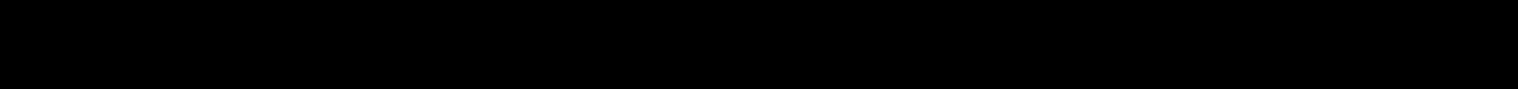

Оборачиваемость активов

### 5. Абсолютные показатели прибыли
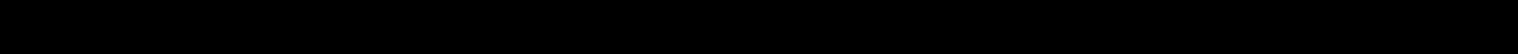

Валовая прибыль
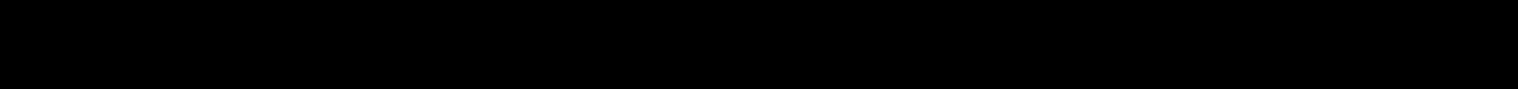

Прибыль до налогообложения

Чистая прибыль
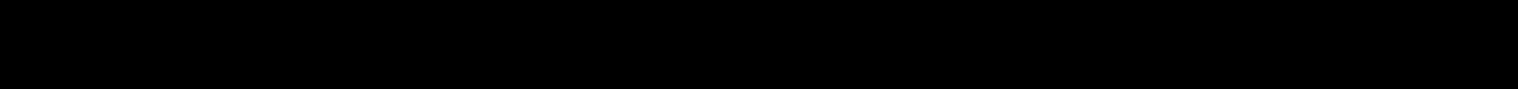